# Validasi Sederhana: Model vs Jurnal

Referensi: *Allansson, Toffolo & Samuelsson (2026), "Spatially-explicit optimization of hydrogen supply chains utilizing offshore wind power"*.

Ini versi **sederhana** dari `validasi_jurnal.ipynb`. Rumus dan datanya dibuat sesederhana mungkin:

| Bagian | Versi lengkap | Versi sederhana (notebook ini) |
|---|---|---|
| Data angin | deret Weibull sintetis + kalibrasi | angin berhenti **7 jam setiap minggu** (161 dari 168 jam, hal. 904) |
| Tangki | 3 tangki cascade + gas sisa dari massa jenis | **1 tangki**, separuh isinya gas sisa |
| Kompresor | 3 tingkat tekanan | 1 rumus: 30→100 bar + 80→200 bar |
| Pipa | *general flow equation* + faktor gesek Colebrook | rumus aliran isotermal, faktor gesek tetap |
| Kabel | rugi per km + 2 konverter | rugi tetap 2% |
| Optimasi | enumerasi lokasi & diameter, 8 jenis biaya | 1 LP kecil per lokasi (ukuran elektrolizer & tangki), biaya lain dihitung dengan rumus |

Setiap langkah berisi **satu cell kode yang ditutup tabel perbandingan**, lalu **penjelasan gap**.
Status: ✅ gap ≤ 5% · ⚠️ 5–15% · ❌ > 15%.

**Alur:** 0. Import → 1. Parameter → 2. Data → 3. Rumus fisika → 4. Optimasi & Tabel 3 → 5. Rincian LCOH (Gbr. 2) → 6. Sensitivitas (Gbr. 6) → 7. Rangkuman

## 0. Import & alat bantu perbandingan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

SOLVER = pyo.SolverFactory("highs")
SKOR = []   # semua baris perbandingan, dirangkum di langkah 7


def bandingkan(langkah, baris):
    # baris = list of (besaran, model_saya, jurnal, satuan, sumber)
    rows = []
    for besaran, mine, ref, unit, src in baris:
        if isinstance(mine, str) or isinstance(ref, str):
            gap, status = np.nan, ("✅" if mine == ref else "❌")
        else:
            gap = (mine - ref) / abs(ref) * 100
            status = "✅" if abs(gap) <= 5 else ("⚠️" if abs(gap) <= 15 else "❌")
        rows.append({"Besaran": besaran, "Model saya": mine, "Jurnal": ref, "Satuan": unit,
                     "Gap (%)": gap, "Status": status, "Sumber": src})
    SKOR.extend({"Langkah": langkah, **r} for r in rows)
    num = lambda v: v if isinstance(v, str) else (f"{v:,.0f}" if abs(v) >= 1000 else f"{v:.3g}")
    display(pd.DataFrame(rows).style.format({"Model saya": num, "Jurnal": num, "Gap (%)": "{:+.1f}%"}, na_rep="-")
            .hide(axis="index"))

## 1. Parameter

Hanya parameter yang benar-benar dipakai. Semua dari **Tabel 2** & hal. 899, kecuali yang ditandai `# ESTIMASI`.

In [9]:
P = {
    "i": 0.08,                          # suku bunga
    "price_el": 0.0368,                 # EUR/kWh (36,8 EUR/MWh)
    "elz_capex": 966, "elz_opex": 0.02, "elz_life": 25, "elz_eff": 0.59,
    "desal_capex": 30.6, "desal_opex": 0.00765, "desal_life": 25, "water_l_per_kg": 15, "desal_kwh_per_l": 0.0035,
    "comp_capex": 2440, "comp_opex": 0.04, "comp_life": 15, "comp_eff": 0.80 * 0.95,   # isentropik x motor
    "sto_capex": 740, "sto_opex": 0.005, "sto_life": 25,
    "sto_residual": 0.5,                # ESTIMASI: separuh isi tangki cascade tidak bisa dipakai (gas sisa)
    "hvdc_capex": 8.3, "hvdc_opex": 0.002, "hvdc_life": 25, "hvdc_onshore": 1.25,
    "cable_loss": 0.02,                 # ESTIMASI: 2 konverter x 1% (rugi per km diabaikan, hanya 0,0035%/km)
    "pipe_opex": 0.02, "pipe_life": 25, "pipe_offshore": 1.7,
    "sub_hvdc": 308 + 34, "sub_pipe": 130, "sub_opex": 0.01, "sub_life": 25,   # gardu laut + darat (EUR/kW)
    "offshore_factor": 1.5,             # alat di laut +50%
}
LHV = 33.33   # kWh/kg H2


def F(name, P=P):
    # Biaya per tahun untuk setiap 1 EUR investasi = anuitas (Pers. 2) + OPEX (Pers. 3)
    i, L = P["i"], P[f"{name}_life"]
    return i / (1 - (1 + i) ** -L) + P[f"{name}_opex"]


kwh_elz = LHV / P["elz_eff"]
bandingkan("1. Parameter", [
    ("Listrik elektrolizer per kg H2", kwh_elz, 90.3e3 * 0.848 * 8760 / 11904e3, "kWh/kg", "dihitung balik dari Tabel 3"),
    ("Faktor biaya tahunan elektrolizer", F("elz"), 0.84 * 11904e3 / (90.3e3 * 966), "1/tahun", "dihitung balik dari Gbr. 2 & Tabel 3"),
])

Besaran,Model saya,Jurnal,Satuan,Gap (%),Status,Sumber
Listrik elektrolizer per kg H2,56.5,56.4,kWh/kg,+0.3%,✅,dihitung balik dari Tabel 3
Faktor biaya tahunan elektrolizer,0.114,0.115,1/tahun,-0.8%,✅,dihitung balik dari Gbr. 2 & Tabel 3


**Penjelasan gap:** keduanya hampir nol. Artinya efisiensi 59% dan rumus anuitas 8%/25 tahun + OPEX 2% sama dengan yang dipakai jurnal.
Baris kedua juga menunjukkan bahwa jurnal **tidak** memasukkan biaya ganti *stack* ke biaya elektrolizer. Jika dimasukkan, faktornya jauh lebih besar.

## 2. Data permintaan & angin

- **Permintaan:** ferry mengisi 16 ton pada 06:00 & 15:00 setiap hari, ditambah Jumat & Minggu 21:00 pada minggu 25–32 (musim ramai).
- **Angin:** jurnal hanya menyebut sistem butuh angin **161 dari 168 jam per minggu** (hal. 904). Jadi datanya dibuat sesederhana itu:
  ladang angin (4050 MW, jauh lebih besar dari elektrolizer) **mati 7 jam setiap Rabu 08:00–15:00**, tepat sebelum pengisian sore
  (kasus paling berat), dan menyala di jam lainnya.

In [10]:
idx = pd.date_range("2021-01-01", periods=8760, freq="h")
week = idx.isocalendar().week.values
PEAK = (week >= 25) & (week <= 32)

demand = np.zeros(8760)
for t, ts in enumerate(idx):
    if ts.hour in (6, 15):
        demand[t] += 16000
    if PEAK[t] and (ts.dayofweek, ts.hour) in ((4, 21), (6, 21)):
        demand[t] += 16000

wind_on = np.array([not (ts.dayofweek == 2 and 8 <= ts.hour < 15) for ts in idx])   # True = angin ada

bandingkan("2. Data", [
    ("Permintaan tahunan", demand.sum() / 1000, 11904, "ton", "hal. 899"),
    ("Kenaikan permintaan musim ramai", (demand[PEAK].sum() / PEAK.sum()) / (demand[~PEAK].sum() / (~PEAK).sum()) * 100 - 100,
     15, "%", "hal. 898 ('almost 15%')"),
    ("Jam angin tersedia per minggu", wind_on.sum() / (8760 / 168), 161, "jam", "hal. 904"),
])

Besaran,Model saya,Jurnal,Satuan,Gap (%),Status,Sumber
Permintaan tahunan,"11,936","11,904",ton,+0.3%,✅,hal. 899
Kenaikan permintaan musim ramai,14.3,15,%,-4.8%,✅,hal. 898 ('almost 15%')
Jam angin tersedia per minggu,161,161,jam,+0.0%,✅,hal. 904


**Penjelasan gap:**
- Permintaan +0,3%: jadwal tebakan menghasilkan 746 pengisian, sedangkan jurnal 744 (11.904 / 16). Selisih 2 kali pengisian.
- Kenaikan musim ramai: 16 vs 14 pengisian per minggu, yaitu +14%, sesuai "almost 15%".
- Jam angin: sama persis karena memang dibuat dari angka jurnal. Namun pola "mati 7 jam setiap minggu" jauh lebih teratur
  dari angin sungguhan. Ini sumber gap terbesar nanti di ukuran **tangki** (Langkah 5).

## 3. Rumus fisika sederhana

**Kompresor** (kerja isentropik gas ideal):
$$w = \frac{k}{k-1}\,\frac{R\,T}{\eta}\left[\left(\frac{p_2}{p_1}\right)^{\frac{k-1}{k}} - 1\right]$$
Kompresor 1: 30→100 bar (dari elektrolizer ke pipa). Kompresor 2: 80→200 bar (dari pipa ke tangki; 200 bar = tekanan tengah cascade 67/200/350).

**Kapasitas pipa** (aliran isotermal, faktor gesek tetap λ = 0,017):
$$\dot m = A\sqrt{\frac{(p_1^2 - p_2^2)\,D}{\lambda\,L\,R\,T\,Z}}, \qquad p_1 = 100 \text{ bar},\; p_2 = 80 \text{ bar}$$
Diameter dipilih yang terkecil (dalam cm bulat) yang sanggup mengalirkan produksi puncak.

In [11]:
R_H2, T_GAS, Z = 4124.0, 288.15, 1.05


def comp_kwh_per_kg(p1, p2, k=1.41):
    if p2 <= p1:
        return 0.0
    return k / (k - 1) * R_H2 * 298.15 * ((p2 / p1) ** ((k - 1) / k) - 1) / 3.6e6 / P["comp_eff"]


def pipe_flow_kgph(D, L_km, lam=0.017):
    A = np.pi * D**2 / 4
    return A * np.sqrt(((100e5) ** 2 - (80e5) ** 2) * D / (lam * L_km * 1000 * R_H2 * T_GAS * Z)) * 3600


def pipe_diameter_cm(flow_kgph, L_km):
    return next(d for d in range(5, 60) if pipe_flow_kgph(d / 100, L_km) >= flow_kgph)


w1 = comp_kwh_per_kg(30, 100)
w2 = comp_kwh_per_kg(80, 200)
w2_no_pipe = comp_kwh_per_kg(30, 200)      # jika elektrolizer di pelabuhan (tanpa pipa)
kwh_desal = P["water_l_per_kg"] * P["desal_kwh_per_l"]
print(f"Kompresor 1: {w1:.2f} kWh/kg | Kompresor 2: {w2:.2f} kWh/kg | Desalinasi: {kwh_desal:.3f} kWh/kg")

flow_journal = 90.3e3 / kwh_elz     # produksi puncak elektrolizer jurnal (kg/jam)
kwh_total = (kwh_elz + w1 + kwh_desal) / (1 - P["cable_loss"]) + w2
bandingkan("3. Fisika", [
    ("Diameter pipa, 80 km (Layout 1)", pipe_diameter_cm(flow_journal, 80), 11, "cm", "Tabel 3"),
    ("Diameter pipa, 23 km (Layout 2)", pipe_diameter_cm(flow_journal, 23), 9, "cm", "Tabel 3"),
    ("Listrik total per kg H2", kwh_total, 2.16 / 0.0368, "kWh/kg", "dihitung balik dari Gbr. 2"),
])

Kompresor 1: 0.65 kWh/kg | Kompresor 2: 0.47 kWh/kg | Desalinasi: 0.052 kWh/kg


Besaran,Model saya,Jurnal,Satuan,Gap (%),Status,Sumber
"Diameter pipa, 80 km (Layout 1)",11,11,cm,+0.0%,✅,Tabel 3
"Diameter pipa, 23 km (Layout 2)",9,9,cm,+0.0%,✅,Tabel 3
Listrik total per kg H2,58.8,58.7,kWh/kg,+0.2%,✅,dihitung balik dari Gbr. 2


**Penjelasan gap:**
- Diameter pipa sama dengan jurnal. Rumus sederhana dengan λ tetap sudah cukup untuk dua panjang pipa ini, walaupun jurnal memakai
  *general flow equation* (Pers. 10).
- Listrik per kg hanya beda sedikit. Kompresor 2 dianggap selalu menekan ke 200 bar. Di jurnal sebagian H₂ masuk tangki 67 bar
  tanpa kompresor dan sebagian lagi ke 350 bar, dan rata-ratanya kebetulan mirip.

## 4. Optimasi & perbandingan Tabel 3

Untuk setiap lokasi elektrolizer (`offshore` / `landfall` / `port`):
1. Hitung **biaya tahunan per 1 kg/jam kapasitas** (elektrolizer, desalinasi, kompresor, kabel, gardu; ×1,5 jika di laut).
2. **LP kecil** mencari kapasitas `cap` (kg/jam) dan tangki `sto` (kg) termurah:

$$\min\; c_{cap}\cdot cap + c_{sto}\cdot sto \quad\text{dengan}\quad
h_t \le cap,\;\; h_t = 0 \text{ saat angin mati},\;\; s_t = s_{t-1} + h_t - d_t,\;\; 0 \le s_t \le sto$$

3. Tambahkan biaya pipa (diameter dari Langkah 3) dan listrik (kWh/kg × produksi), lalu bagi dengan produksi untuk mendapat **LCOH**.
4. Lokasi termurah = pilihan model, setara variabel biner $EP_z$ di jurnal (Pers. 7–8).

In [12]:
LAYOUTS = {"Layout 1": (30, 80), "Layout 2": (80, 23)}   # (km laut, km darat), Tabel 1


def site(layout, name, P=P):
    off, on = layout
    cable_km = {"offshore": (0, 0), "landfall": (off, 0), "port": (off, on)}[name]   # (laut, darat)
    pipe_km = {"offshore": (off, on), "landfall": (0, on), "port": (0, 0)}[name]
    has_cable, has_pipe = sum(cable_km) > 0, sum(pipe_km) > 0
    kwh_elz = LHV / P["elz_eff"]
    eta = 1 - P["cable_loss"] if has_cable else 1.0
    kwh_site = kwh_elz + (w1 if has_pipe else 0) + kwh_desal           # listrik di lokasi elektrolizer
    w_c2 = w2 if has_pipe else w2_no_pipe
    cbf = P["offshore_factor"] if name == "offshore" else 1.0
    cable_kw_per_kgh = kwh_site / eta                                  # beban kabel per 1 kg/jam
    # biaya tahunan per 1 kg/jam kapasitas
    c = {
        "Electrolyzer": kwh_elz * P["elz_capex"] * cbf * F("elz", P),
        "Desalination": P["water_l_per_kg"] * P["desal_capex"] * cbf * F("desal", P),
        "Compressors": ((w1 if has_pipe else 0) * cbf + w_c2) * P["comp_capex"] * F("comp", P),
        "HVDC": cable_kw_per_kgh * P["hvdc_capex"] * (cable_km[0] + P["hvdc_onshore"] * cable_km[1]) * F("hvdc", P),
        "Station": cable_kw_per_kgh * (P["sub_hvdc"] if has_cable else P["sub_pipe"]) * F("sub", P),
    }
    return dict(name=name, per_kgh=c, kwh_per_kg=kwh_site / eta + w_c2, pipe_km=pipe_km, has_pipe=has_pipe)


def size_lp(c_cap, c_sto, demand, wind_on):
    m = pyo.ConcreteModel()
    T = range(len(demand))
    m.h = pyo.Var(T, bounds=lambda m, t: (0, None if wind_on[t] else 0))   # produksi H2 (kg/jam)
    m.cap = pyo.Var(domain=pyo.NonNegativeReals)                           # kapasitas (kg/jam)
    m.s = pyo.Var(T, domain=pyo.NonNegativeReals)                          # isi tangki terpakai (kg)
    m.sto = pyo.Var(domain=pyo.NonNegativeReals)                           # kapasitas tangki terpakai (kg)
    m.c_cap = pyo.Constraint(T, rule=lambda m, t: m.h[t] <= m.cap)
    m.c_bal = pyo.Constraint(T, rule=lambda m, t: m.s[t] == m.s[t - 1 if t else len(T) - 1] + m.h[t] - demand[t])
    m.c_sto = pyo.Constraint(T, rule=lambda m, t: m.s[t] <= m.sto)
    m.obj = pyo.Objective(expr=c_cap * m.cap + c_sto * m.sto)
    SOLVER.solve(m)
    return pyo.value(m.cap), pyo.value(m.sto), np.array([pyo.value(m.h[t]) for t in T]), np.array([pyo.value(m.s[t]) for t in T])


def evaluate(layout, name, demand=demand, wind_on=wind_on, P=P):
    s = site(layout, name, P)
    c_sto = P["sto_capex"] * F("sto", P) / (1 - P["sto_residual"])     # per kg yang bisa dipakai
    cap, sto, h, soc = size_lp(sum(s["per_kgh"].values()), c_sto, demand, wind_on)
    H = demand.sum()
    cost = {k: v * cap for k, v in s["per_kgh"].items()}
    d_cm = pipe_diameter_cm(cap, sum(s["pipe_km"])) if s["has_pipe"] else None
    eq_km = P["pipe_offshore"] * s["pipe_km"][0] + s["pipe_km"][1]
    cost["Pipeline"] = (4.66 * (d_cm / 100) ** 2 + 0.82 * d_cm / 100 + 0.45) * 1e6 * eq_km * F("pipe", P) if d_cm else 0.0
    cost["Storage"] = c_sto * sto
    cost["Electricity"] = P["price_el"] * s["kwh_per_kg"] * H
    elz_mw = cap * LHV / P["elz_eff"] / 1000
    return dict(site=name, LCOH=sum(cost.values()) / H, elz_MW=elz_mw, CF=h.sum() / (cap * len(h)), d_cm=d_cm,
                sto_total_t=sto / (1 - P["sto_residual"]) / 1000, breakdown={k: v / H for k, v in cost.items()},
                h=h, soc=soc)


def optimize(layout, **kw):
    per_site = {n: evaluate(layout, n, **kw) for n in ("offshore", "landfall", "port")}
    best = min(per_site.values(), key=lambda r: r["LCOH"])
    best["all"] = {n: r["LCOH"] for n, r in per_site.items()}
    return best


res = {name: optimize(lay) for name, lay in LAYOUTS.items()}
for name, r in res.items():
    print(name, "LCOH per lokasi:", {k: round(v, 3) for k, v in r["all"].items()})

T3 = {"Layout 1": (4.47, 90.3, 84.8, 11), "Layout 2": (4.46, 90.3, 84.8, 9)}
rows = []
for name, r in res.items():
    lc, mw, cf, d = T3[name]
    rows += [(f"{name}: lokasi elektrolizer", r["site"], "landfall", "", "hal. 903, Gbr. 3"),
             (f"{name}: LCOH", r["LCOH"], lc, "EUR/kg", "Tabel 3"),
             (f"{name}: kapasitas elektrolizer", r["elz_MW"], mw, "MW", "Tabel 3"),
             (f"{name}: capacity factor", r["CF"] * 100, cf, "%", "Tabel 3"),
             (f"{name}: diameter pipa", r["d_cm"], d, "cm", "Tabel 3")]
bandingkan("4. Tabel 3", rows)

Layout 1 LCOH per lokasi: {'offshore': np.float64(4.674), 'landfall': np.float64(4.328), 'port': np.float64(4.484)}
Layout 2 LCOH per lokasi: {'offshore': np.float64(4.838), 'landfall': np.float64(4.31), 'port': np.float64(4.354)}


Besaran,Model saya,Jurnal,Satuan,Gap (%),Status,Sumber
Layout 1: lokasi elektrolizer,landfall,landfall,,-,✅,"hal. 903, Gbr. 3"
Layout 1: LCOH,4.33,4.47,EUR/kg,-3.2%,✅,Tabel 3
Layout 1: kapasitas elektrolizer,91.5,90.3,MW,+1.4%,✅,Tabel 3
Layout 1: capacity factor,84.1,84.8,%,-0.8%,✅,Tabel 3
Layout 1: diameter pipa,11,11,cm,+0.0%,✅,Tabel 3
Layout 2: lokasi elektrolizer,landfall,landfall,,-,✅,"hal. 903, Gbr. 3"
Layout 2: LCOH,4.31,4.46,EUR/kg,-3.4%,✅,Tabel 3
Layout 2: kapasitas elektrolizer,89.8,90.3,MW,-0.5%,✅,Tabel 3
Layout 2: capacity factor,85.7,84.8,%,+1.1%,✅,Tabel 3
Layout 2: diameter pipa,9,9,cm,+0.0%,✅,Tabel 3


**Penjelasan gap:** lihat juga rincian di Langkah 5.
- **Lokasi** sama dengan jurnal: hybrid (kabel di laut, pipa di darat). Pilihan `port` dan `offshore` lebih mahal di kedua layout.
- **Kapasitas elektrolizer & capacity factor** dekat dengan jurnal. Ukurannya ditentukan oleh minggu musim ramai:
  256 ton / 161 jam ≈ 1.590 kg/jam ≈ 90 MW. Di Layout 1 model memilih sedikit lebih besar (91,5 MW) dengan tangki lebih kecil,
  karena biaya per kW-nya (kabel 30 km) lebih murah daripada di Layout 2 (kabel 80 km). Di Layout 2 berlaku kebalikannya
  (89,8 MW, tangki lebih besar). Jurnal juga melaporkan perbedaan tangki kecil antar layout (hal. 903).
- **LCOH sekitar 3% lebih rendah** dari jurnal. Hampir seluruh selisihnya (≈0,14 EUR/kg) berasal dari biaya tangki yang lebih kecil (Langkah 5).
- Urutan layout sama dengan jurnal: Layout 2 sedikit lebih murah daripada Layout 1.

## 5. Rincian LCOH vs Gambar 2

Besaran,Model saya,Jurnal,Satuan,Gap (%),Status,Sumber
Layout 1: HVDC,0.189,0.19,EUR/kg,-0.7%,✅,Gbr. 2
Layout 1: Pipeline,0.455,0.46,EUR/kg,-1.2%,✅,Gbr. 2
Layout 1: Station,0.281,0.28,EUR/kg,+0.3%,✅,Gbr. 2
Layout 1: Compressors,0.0582,0.06,EUR/kg,-3.1%,✅,Gbr. 2
Layout 1: Storage,0.332,0.49,EUR/kg,-32.2%,❌,Gbr. 2
Layout 1: Electrolyzer,0.842,0.84,EUR/kg,+0.3%,✅,Gbr. 2
Layout 1: Electricity,2.16,2.16,EUR/kg,+0.2%,✅,Gbr. 2
Layout 1: ukuran tangki total,54.3,79.9,ton,-32.0%,❌,dihitung balik dari Gbr. 2
Layout 2: HVDC,0.494,0.5,EUR/kg,-1.2%,✅,Gbr. 2
Layout 2: Pipeline,0.123,0.12,EUR/kg,+2.5%,✅,Gbr. 2


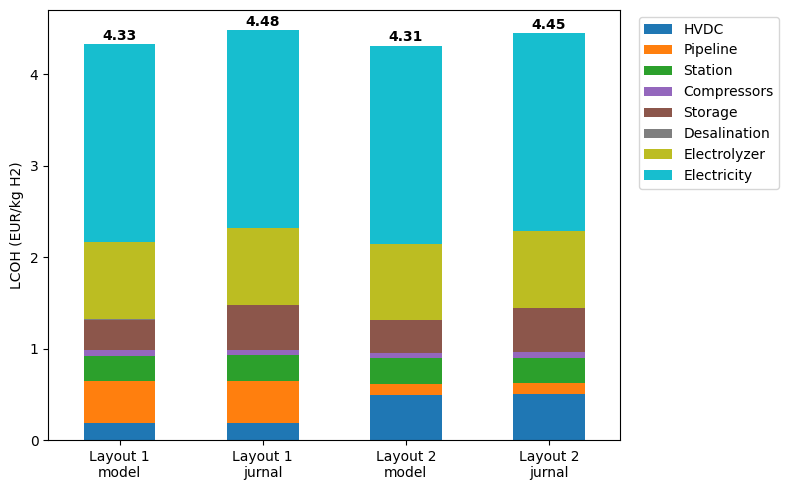

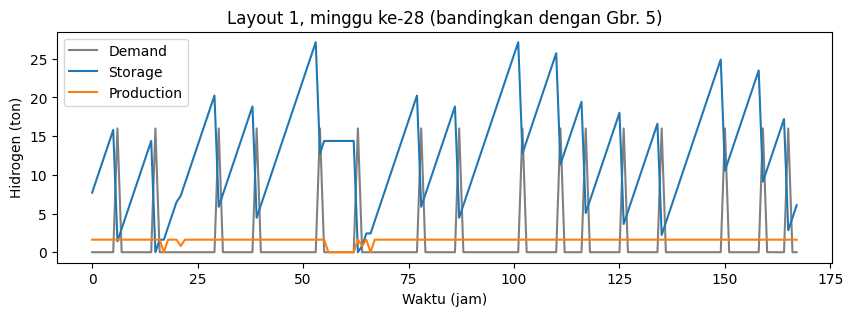

In [6]:
ORDER = ["HVDC", "Pipeline", "Station", "Compressors", "Storage", "Desalination", "Electrolyzer", "Electricity"]
FIG2 = {"Layout 1": dict(HVDC=0.19, Pipeline=0.46, Station=0.28, Compressors=0.06, Storage=0.49, Desalination=0.0,
                         Electrolyzer=0.84, Electricity=2.16),
        "Layout 2": dict(HVDC=0.50, Pipeline=0.12, Station=0.28, Compressors=0.06, Storage=0.49, Desalination=0.0,
                         Electrolyzer=0.84, Electricity=2.16)}
STO_JOURNAL_T = 0.49 * 11904e3 / F("sto") / P["sto_capex"] / 1000      # ukuran tangki tersirat (~80 t)

rows = []
for name, r in res.items():
    rows += [(f"{name}: {k}", r["breakdown"][k], FIG2[name][k], "EUR/kg", "Gbr. 2") for k in ORDER if k != "Desalination"]
    rows.append((f"{name}: ukuran tangki total", r["sto_total_t"], STO_JOURNAL_T, "ton", "dihitung balik dari Gbr. 2"))
bandingkan("5. Gambar 2", rows)

bars = {}
for name, r in res.items():
    bars[f"{name}\nmodel"] = [r["breakdown"][k] for k in ORDER]
    bars[f"{name}\njurnal"] = [FIG2[name][k] for k in ORDER]
bd = pd.DataFrame(bars, index=ORDER)
ax = bd.T.plot(kind="bar", stacked=True, figsize=(8, 5), rot=0, colormap="tab10")
for i, c in enumerate(bd.columns):
    ax.text(i, bd[c].sum() + 0.05, f"{bd[c].sum():.2f}", ha="center", fontweight="bold")
ax.set_ylabel("LCOH (EUR/kg H2)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Isi tangki 1 minggu musim ramai (bandingkan dengan Gbr. 5: naik turun antara ~0 dan ~40 ton)
r = res["Layout 1"]
w = week == 28
pd.DataFrame({"Demand": demand[w] / 1000, "Storage": r["soc"][w] / 1000, "Production": r["h"][w] / 1000}).plot(
    figsize=(10, 3), color=["gray", "tab:blue", "tab:orange"], title="Layout 1, minggu ke-28 (bandingkan dengan Gbr. 5)")
plt.xlabel("Waktu (jam)")
plt.ylabel("Hidrogen (ton)")
plt.show()

**Penjelasan gap:**
- **Listrik, elektrolizer, kabel (HVDC), gardu (Station), pipa:** gap kecil. Rumus biayanya sama dengan jurnal (Pers. 2–5),
  sedangkan kapasitas dan diameternya sudah dekat di Langkah 4.
- **Kompresor:** dekat, karena 80→200 bar kebetulan mendekati rata-rata tiga tangki cascade.
- **Tangki (gap terbesar):** di grafik, isi tangki model hanya naik-turun sekitar 27 ton, sedangkan Gbr. 5 jurnal sekitar 40 ton.
  Penyebabnya data angin: di model angin mati **tepat 7 jam setiap minggu**, sementara angin sungguhan kadang mati lebih lama
  (misalnya 15–20 jam) sehingga butuh cadangan lebih besar. Jika ingin gap ini mengecil, data angin perlu dibuat lebih realistis
  seperti di `validasi_jurnal.ipynb`. Konsekuensinya rumus dan datanya jadi lebih rumit.

## 6. Sensitivitas vs Gambar 6

Ubah satu parameter ke nilai rendah/tinggi (Tabel 4), hitung ulang di lokasi terpilih, lalu bandingkan **perubahan LCOH (%)** dengan teks hal. 906.

In [7]:
SENS = {"Electrolyzer cost": ("elz_capex", 644, 1288),
        "LCOE": ("price_el", 0.0276, 0.046),
        "Electrolyzer efficiency": ("elz_eff", 0.505, 0.71)}
JOURNAL = {("Layout 1", "Electrolyzer cost"): (-6, 6), ("Layout 2", "Electrolyzer cost"): (-6, 6),
           ("Layout 1", "LCOE"): (-12, 12), ("Layout 2", "LCOE"): (-12, 12),
           ("Layout 1", "Electrolyzer efficiency"): (12.9, -12.8), ("Layout 2", "Electrolyzer efficiency"): (14.1, -14.0)}

rows = []
for name, lay in LAYOUTS.items():
    base = res[name]
    for label, (key, lo, hi) in SENS.items():
        for case, val, ref in (("Low", lo, JOURNAL[(name, label)][0]), ("High", hi, JOURNAL[(name, label)][1])):
            P2 = {**P, key: val}
            r = evaluate(lay, base["site"], P=P2)
            rows.append((f"{name}: {label} {case}", (r["LCOH"] / base["LCOH"] - 1) * 100, ref, "% LCOH", "hal. 906"))
bandingkan("6. Sensitivitas", rows)

Besaran,Model saya,Jurnal,Satuan,Gap (%),Status,Sumber
Layout 1: Electrolyzer cost Low,-6.49,-6,% LCOH,-8.1%,⚠️,hal. 906
Layout 1: Electrolyzer cost High,6.47,6,% LCOH,+7.9%,⚠️,hal. 906
Layout 1: LCOE Low,-12.5,-12,% LCOH,-4.2%,✅,hal. 906
Layout 1: LCOE High,12.5,12,% LCOH,+4.2%,✅,hal. 906
Layout 1: Electrolyzer efficiency Low,13.3,12.9,% LCOH,+3.3%,✅,hal. 906
Layout 1: Electrolyzer efficiency High,-13.4,-12.8,% LCOH,-4.6%,✅,hal. 906
Layout 2: Electrolyzer cost Low,-6.49,-6,% LCOH,-8.1%,⚠️,hal. 906
Layout 2: Electrolyzer cost High,6.39,6,% LCOH,+6.5%,⚠️,hal. 906
Layout 2: LCOE Low,-12.6,-12,% LCOH,-4.7%,✅,hal. 906
Layout 2: LCOE High,12.6,12,% LCOH,+4.7%,✅,hal. 906


**Penjelasan gap:**
- **Arah dan urutan** sama dengan jurnal: efisiensi elektrolizer paling berpengaruh, lalu LCOE, lalu biaya elektrolizer.
  Layout 2 juga lebih peka terhadap efisiensi daripada Layout 1, karena kabelnya lebih panjang.
- **Gap ⚠️ pada biaya elektrolizer (6,5% vs 6%)** bukan karena rumusnya beda. Perubahan biaya dalam EUR/kg hampir sama
  (≈0,28 EUR/kg), tetapi dibagi LCOH dasar yang lebih kecil (4,33 vs 4,47), sehingga persentasenya terlihat lebih besar.
  Akar masalahnya tetap tangki yang lebih kecil di Langkah 5.

## 7. Rangkuman

In [8]:
skor = pd.DataFrame(SKOR)
num = skor.dropna(subset=["Gap (%)"])
summary = (skor.groupby("Langkah", sort=False)["Status"].value_counts().unstack(fill_value=0)
           .reindex(columns=["✅", "⚠️", "❌"], fill_value=0))
summary["median |gap| (%)"] = num.groupby("Langkah", sort=False)["Gap (%)"].apply(lambda g: g.abs().median())
display(summary.round(1))
print(f"Total {len(skor)} perbandingan | median |gap| = {num['Gap (%)'].abs().median():.1f}%")

Status,✅,⚠️,❌,median |gap| (%)
Langkah,,,,
1. Parameter,2,0,0,0.5
2. Data,3,0,0,0.3
3. Fisika,3,0,0,0.0
4. Tabel 3,10,0,0,0.9
5. Gambar 2,12,0,4,1.6
6. Sensitivitas,8,4,0,4.6


Total 46 perbandingan | median |gap| = 2.1%


### Kesimpulan

| Penyederhanaan | Dampak pada gap |
|---|---|
| Angin mati 7 jam/minggu, teratur | tangki lebih kecil dari jurnal → **biaya tangki & LCOH lebih rendah** |
| 1 tangki, gas sisa 50% | kecil; angka 50% diambil dari jurnal (≈40 t terpakai dari ≈80 t total) |
| Kompresor 80→200 bar | kecil (rata-rata tekanan cascade) |
| Pipa: rumus isotermal, λ tetap | tidak ada; diameter sama dengan jurnal |
| Rugi kabel tetap 2% | sangat kecil (rugi per km hanya 0,0035%/km) |
| Ganti stack tidak dihitung | sama dengan jurnal (Langkah 1) |

Kesimpulan utama jurnal tetap tereproduksi: **elektrolizer diletakkan di titik darat pertama** (kabel HVDC di laut, pipa H₂ di darat),
dan **LCOH didominasi listrik** (sekitar 2,16 EUR/kg).